# Tugas Praktikum Data Mining — Evaluasi Model Klasifikasi
**Tugas 1 sampai Tugas 4**

Nama: AUDITYA MEROSYA PUTRI | NIM: 24343001 

Nama: Muhammad Zahran       | NIM: 24343077

Nama: Muhammad Riyad Anwari | NIM: 24343044

Notebook ini berdiri sendiri: dataset dibangkitkan di dalam notebook (Tugas 2) dan juga disimpan sebagai `dataset_fraud.csv`. Jalankan sel dari atas ke bawah. Di bawah setiap sel kode terdapat **Analisis**.

## Tugas 1 — Hitung Manual
Diketahui TP=24, TN=156, FP=12, FN=8. Susun confusion matrix, hitung accuracy, precision, recall, F1-score, lalu interpretasikan FP dan FN dalam konteks fraud.

In [1]:
import numpy as np
import pandas as pd

TP, TN, FP, FN = 24, 156, 12, 8

# Susunan scikit-learn: [[TN, FP], [FN, TP]]
cm_manual = pd.DataFrame([[TN, FP], [FN, TP]],
                         index=['Aktual normal (0)', 'Aktual fraud (1)'],
                         columns=['Prediksi normal (0)', 'Prediksi fraud (1)'])
print('Confusion matrix:')
print(cm_manual)

total = TP + TN + FP + FN
acc = (TP + TN) / total
prec = TP / (TP + FP)
rec = TP / (TP + FN)
f1_ = 2 * prec * rec / (prec + rec)

print(f'\nTotal data = {total}')
print(f'Accuracy  = ({TP}+{TN})/{total} = {acc:.4f}')
print(f'Precision = {TP}/({TP}+{FP}) = {prec:.4f}')
print(f'Recall    = {TP}/({TP}+{FN}) = {rec:.4f}')
print(f'F1-score  = 2 x {prec:.4f} x {rec:.4f} / ({prec:.4f}+{rec:.4f}) = {f1_:.4f}')

Confusion matrix:
                   Prediksi normal (0)  Prediksi fraud (1)
Aktual normal (0)                  156                  12
Aktual fraud (1)                     8                  24

Total data = 200
Accuracy  = (24+156)/200 = 0.9000
Precision = 24/(24+12) = 0.6667
Recall    = 24/(24+8) = 0.7500
F1-score  = 2 x 0.6667 x 0.7500 / (0.6667+0.7500) = 0.7059


**Analisis Tugas 1**

- Total 200 transaksi: 32 fraud aktual (TP+FN) dan 168 normal aktual (TN+FP).
- **Accuracy = 180/200 = 0,90 (90%)**: 9 dari 10 transaksi diklasifikasikan benar.
- **Precision = 24/36 = 0,6667 (66,67%)**: dari 36 alarm fraud, 24 benar-benar fraud dan 12 alarm palsu.
- **Recall = 24/32 = 0,75 (75%)**: model menemukan 24 dari 32 fraud aktual.
- **F1-score = 0,7059 (70,59%)**: rata-rata harmonik precision dan recall, sedikit lebih dekat ke nilai yang lebih rendah (precision).
- **FP = 12:** transaksi normal yang salah ditandai fraud. Dampaknya pelanggan terganggu (transaksi diblokir atau harus verifikasi ulang) dan beban kerja verifikasi bertambah.
- **FN = 8:** fraud yang lolos tanpa terdeteksi. Dampaknya kerugian finansial langsung, yang umumnya lebih mahal daripada FP dalam deteksi fraud.

## Tugas 2 — Verifikasi Python
Jalankan Bagian 4.1–4.5. Lampirkan dataset awal, confusion matrix, perhitungan manual dari TP/TN/FP/FN aktual, dan hasil scikit-learn. Jelaskan kesesuaian hasil.

In [2]:
# --- Membangkitkan dataset sintetis (4.1) ---
rng = np.random.default_rng(42)
n = 500
amount = rng.lognormal(mean=5.0, sigma=1.0, size=n)
hour = rng.integers(0, 24, n)
new_device = rng.binomial(1, 0.25, n)
foreign_ip = rng.binomial(1, 0.12, n)

score = -4.5 + 0.45*(amount > 300) + 1.1*new_device + 1.5*foreign_ip + 0.7*(hour < 5)
prob = 1/(1+np.exp(-score))
isFraud = rng.binomial(1, prob)

df = pd.DataFrame({'amount': amount.round(2), 'hour': hour,
                   'new_device': new_device, 'foreign_ip': foreign_ip,
                   'isFraud': isFraud})
df.to_csv('dataset_fraud.csv', index=False)   # dataset disimpan ke file

print('Dataset awal (5 baris pertama):')
display(df.head())
print('Jumlah data:', len(df))
print('Distribusi kelas:')
print(df['isFraud'].value_counts())
print('Proporsi fraud:', round(df['isFraud'].mean(), 4))

Dataset awal (5 baris pertama):


,amount,hour,new_device,foreign_ip,isFraud
0,201.28,9,0,0,0
1,52.46,8,0,0,0
2,314.33,17,1,0,0
3,380.15,3,0,0,0
4,21.09,5,1,0,0


Jumlah data: 500
Distribusi kelas:
isFraud
0    484
1     16
Name: count, dtype: int64
Proporsi fraud: 0.032


In [3]:
# --- Membagi data dan melatih model (4.2) ---
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

X = df.drop(columns='isFraud')
y = df['isFraud']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)

model = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print('Data latih:', len(y_train), '| Data uji:', len(y_test))
print('Distribusi data uji:', y_test.value_counts().to_dict())

Data latih: 350 | Data uji: 150
Distribusi data uji: {0: 145, 1: 5}


TP=2, TN=113, FP=32, FN=3


,Prediksi normal (0),Prediksi fraud (1)
Aktual normal (0),113,32
Aktual fraud (1),3,2


,Manual,scikit-learn,Sama?
Accuracy,0.7667,0.7667,True
Precision,0.0588,0.0588,True
Recall,0.4000,0.4000,True
F1-score,0.1026,0.1026,True


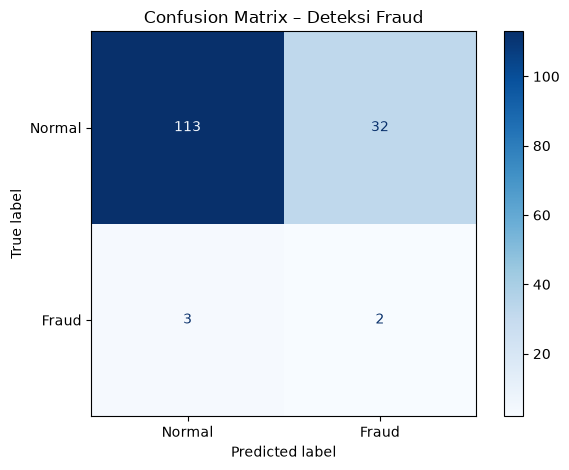

In [4]:
# --- Confusion matrix (4.3), perhitungan manual & scikit-learn (4.4) ---
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print(f'TP={tp}, TN={tn}, FP={fp}, FN={fn}')
display(pd.DataFrame(cm, index=['Aktual normal (0)', 'Aktual fraud (1)'],
                     columns=['Prediksi normal (0)', 'Prediksi fraud (1)']))

accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = 2*precision*recall/(precision+recall) if precision+recall else 0

perbandingan = pd.DataFrame({
    'Manual': [accuracy, precision, recall, f1],
    'scikit-learn': [accuracy_score(y_test, y_pred),
                     precision_score(y_test, y_pred, zero_division=0),
                     recall_score(y_test, y_pred, zero_division=0),
                     f1_score(y_test, y_pred, zero_division=0)]
}, index=['Accuracy', 'Precision', 'Recall', 'F1-score']).round(4)
perbandingan['Sama?'] = np.isclose(perbandingan['Manual'], perbandingan['scikit-learn'])
display(perbandingan)

# --- Visualisasi (4.5) ---
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal', 'Fraud']).plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix – Deteksi Fraud')
plt.tight_layout()
plt.show()

**Analisis Tugas 2**

- **Dataset awal:** 500 transaksi, 16 di antaranya fraud (3,2%), sehingga sangat tidak seimbang. Dataset juga tersimpan di `dataset_fraud.csv`.
- **Confusion matrix aktual:** TP=2, TN=113, FP=32, FN=3 pada 150 data uji (5 fraud, 145 normal).
- **Kesesuaian:** keempat metrik hasil perhitungan manual sama dengan hasil scikit-learn (kolom `Sama?` semuanya `True`). Artinya rumus dan pembacaan sel confusion matrix sudah benar.
- **Hasil:** accuracy 0,767; precision 0,059; recall 0,400; F1 0,103.
- **Interpretasi:** accuracy tampak cukup, tetapi precision dan F1 rendah. Model banyak membunyikan alarm palsu (FP=32) dan masih melewatkan 3 dari 5 fraud (FN=3).

## Tugas 3 — Evaluasi Data Tidak Seimbang
Bandingkan baseline semua normal dan Decision Tree. Jelaskan mengapa accuracy tinggi belum tentu menunjukkan kemampuan mendeteksi fraud.

,Model,Accuracy,Precision fraud,Recall fraud,F1 fraud
0,Baseline (semua normal),0.967,0.000,0.0,0.000
1,Decision Tree,0.767,0.059,0.4,0.103


Fraud pada data uji: 5 dari 150
Fraud tertangkap baseline: 0
Fraud tertangkap Decision Tree: 2

Baseline (semua normal):
              precision    recall  f1-score   support

           0       0.97      1.00      0.98       145
           1       0.00      0.00      0.00         5

    accuracy                           0.97       150
   macro avg       0.48      0.50      0.49       150
weighted avg       0.93      0.97      0.95       150

Decision Tree:
              precision    recall  f1-score   support

           0       0.97      0.78      0.87       145
           1       0.06      0.40      0.10         5

    accuracy                           0.77       150
   macro avg       0.52      0.59      0.48       150
weighted avg       0.94      0.77      0.84       150



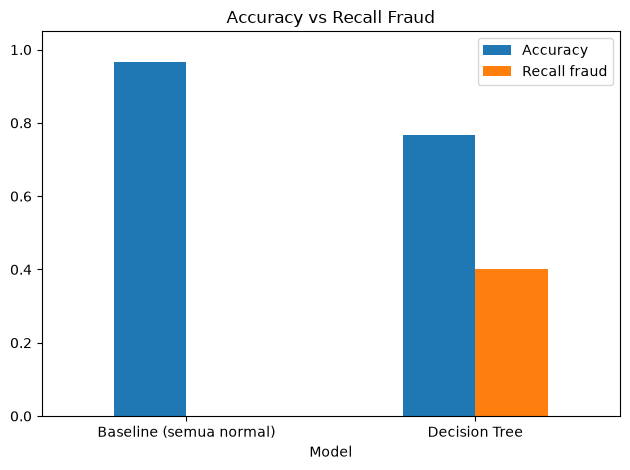

In [5]:
from sklearn.metrics import classification_report

baseline = np.zeros(len(y_test), dtype=int)

def ringkas(nama, pred):
    return {'Model': nama,
            'Accuracy': accuracy_score(y_test, pred),
            'Precision fraud': precision_score(y_test, pred, zero_division=0),
            'Recall fraud': recall_score(y_test, pred, zero_division=0),
            'F1 fraud': f1_score(y_test, pred, zero_division=0)}

tabel_imbalance = pd.DataFrame([ringkas('Baseline (semua normal)', baseline),
                                ringkas('Decision Tree', y_pred)]).round(3)
display(tabel_imbalance)

print('Fraud pada data uji:', int((y_test == 1).sum()), 'dari', len(y_test))
print('Fraud tertangkap baseline:', int(((y_test == 1) & (baseline == 1)).sum()))
print('Fraud tertangkap Decision Tree:', int(((y_test == 1) & (y_pred == 1)).sum()))

print('\nBaseline (semua normal):')
print(classification_report(y_test, baseline, labels=[0, 1], zero_division=0))
print('Decision Tree:')
print(classification_report(y_test, y_pred, labels=[0, 1], zero_division=0))

tabel_imbalance.set_index('Model')[['Accuracy', 'Recall fraud']].plot(kind='bar', rot=0)
plt.title('Accuracy vs Recall Fraud')
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

**Analisis Tugas 3**

| Model | Accuracy | Precision fraud | Recall fraud | F1 fraud |
|---|---|---|---|---|
| Baseline (semua normal) | **0,967** | 0,000 | **0,00** | 0,000 |
| Decision Tree | 0,767 | 0,059 | **0,40** | 0,103 |

- Baseline yang selalu menebak "normal" memperoleh **accuracy 0,967**, lebih tinggi daripada Decision Tree (0,767), padahal tidak mendeteksi fraud sama sekali (**recall fraud = 0**, 0 dari 5 fraud tertangkap).
- Decision Tree menangkap 2 dari 5 fraud (**recall 0,40**), sehingga secara fungsional lebih berguna meskipun accuracy-nya lebih rendah.
- **Mengapa accuracy menyesatkan:** accuracy menghitung semua prediksi benar secara sama rata. Karena 96,7% data uji adalah kelas normal, model yang hanya menebak kelas mayoritas sudah benar hampir di semua kasus. Kemampuan pada kelas minoritas yang justru penting (fraud) tidak tercermin.
- **Metrik yang sesuai:** recall, precision, dan F1 pada kelas fraud (juga PR-AUC atau macro-F1), serta melihat confusion matrix secara langsung.

## Tugas 4 — Eksperimen dan Rekomendasi
Uji empat threshold. Buat tabel precision dan recall, pilih threshold untuk skenario biaya FN lebih tinggi daripada FP, dan berikan argumentasi berbasis hasil.

Nilai probabilitas unik pada data uji: [0.    0.183 0.542 0.849 0.939 1.   ]


,Threshold,Precision,Recall,TP,FP,FN,TN
0,0.2,0.059,0.4,2,32,3,113
1,0.4,0.059,0.4,2,32,3,113
2,0.5,0.059,0.4,2,32,3,113
3,0.7,0.056,0.2,1,17,4,128


Threshold terpilih untuk skenario FN lebih mahal: 0.2
Recall = 0.4 | Precision = 0.059 | FN = 3 | FP = 32


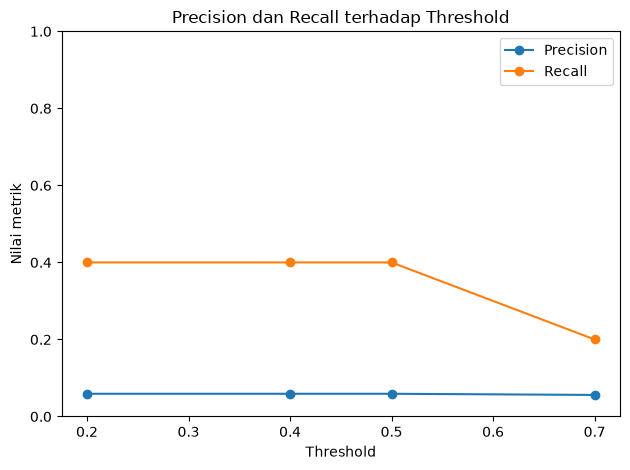

In [6]:
y_prob = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
print('Nilai probabilitas unik pada data uji:', np.unique(y_prob).round(3))

baris = []
for threshold in [0.2, 0.4, 0.5, 0.7]:
    pred = (y_prob >= threshold).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    baris.append({'Threshold': threshold,
                  'Precision': round(precision_score(y_test, pred, zero_division=0), 3),
                  'Recall': round(recall_score(y_test, pred, zero_division=0), 3),
                  'TP': tp_, 'FP': fp_, 'FN': fn_, 'TN': tn_})
tabel_threshold = pd.DataFrame(baris)
display(tabel_threshold)

# Skenario biaya FN > FP: utamakan recall, lalu precision, lalu threshold terendah
pilihan = tabel_threshold.sort_values(['Recall', 'Precision', 'Threshold'],
                                      ascending=[False, False, True]).iloc[0]
print('Threshold terpilih untuk skenario FN lebih mahal:', pilihan['Threshold'])
print('Recall =', pilihan['Recall'], '| Precision =', pilihan['Precision'],
      '| FN =', int(pilihan['FN']), '| FP =', int(pilihan['FP']))

plt.plot(tabel_threshold['Threshold'], tabel_threshold['Precision'], marker='o', label='Precision')
plt.plot(tabel_threshold['Threshold'], tabel_threshold['Recall'], marker='o', label='Recall')
plt.xlabel('Threshold'); plt.ylabel('Nilai metrik'); plt.ylim(0, 1)
plt.title('Precision dan Recall terhadap Threshold')
plt.legend(); plt.tight_layout(); plt.show()

**Analisis Tugas 4**

| Threshold | Precision | Recall | TP | FP | FN | TN |
|---|---|---|---|---|---|---|
| 0,2 | 0,059 | 0,40 | 2 | 32 | 3 | 113 |
| 0,4 | 0,059 | 0,40 | 2 | 32 | 3 | 113 |
| 0,5 | 0,059 | 0,40 | 2 | 32 | 3 | 113 |
| 0,7 | 0,056 | 0,20 | 1 | 17 | 4 | 128 |

- Threshold **0,2, 0,4, dan 0,5 menghasilkan hasil identik**. Pohon dengan `max_depth=4` hanya menghasilkan probabilitas diskret (0; 0,18; 0,54; 0,85; 0,94; 1), sehingga tidak ada prediksi yang berubah di antara 0,2 dan 0,5.
- Pada **0,7**, recall turun dari 0,40 menjadi 0,20 (FN naik menjadi 4), FP turun dari 32 menjadi 17, dan precision hampir tetap (0,056). Menaikkan threshold mengurangi alarm palsu tetapi mengorbankan recall.
- **Rekomendasi untuk skenario biaya FN lebih tinggi daripada FP:** gunakan threshold **0,2** (setara 0,4 dan 0,5). Pada nilai ini recall maksimum (0,40) dan FN paling sedikit (3). Threshold 0,7 tidak dianjurkan karena fraud yang lolos bertambah. Konsekuensinya FP tetap tinggi (32), yang dapat diterima selama kerugian akibat fraud lebih besar daripada biaya verifikasi alarm palsu.
- **Catatan:** data uji hanya memuat 5 fraud, sehingga kesimpulan bersifat indikatif. Untuk hasil yang lebih andal diperlukan data lebih banyak, cross-validation, atau model yang menghasilkan skor probabilitas lebih halus (mis. Random Forest atau Logistic Regression).